# Digital Image Processing using Image Convolution

---

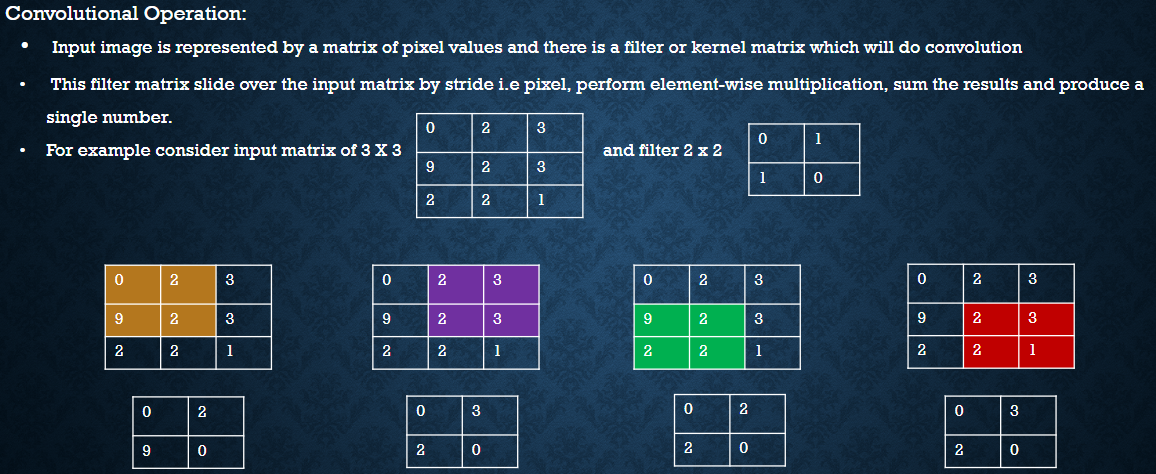

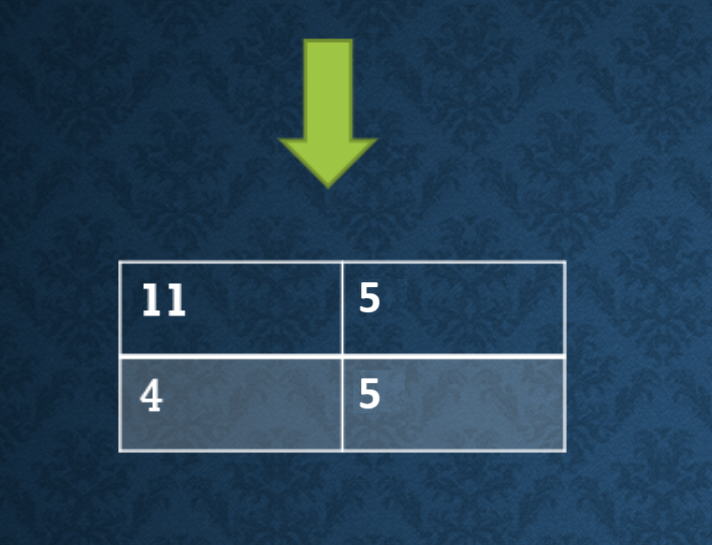

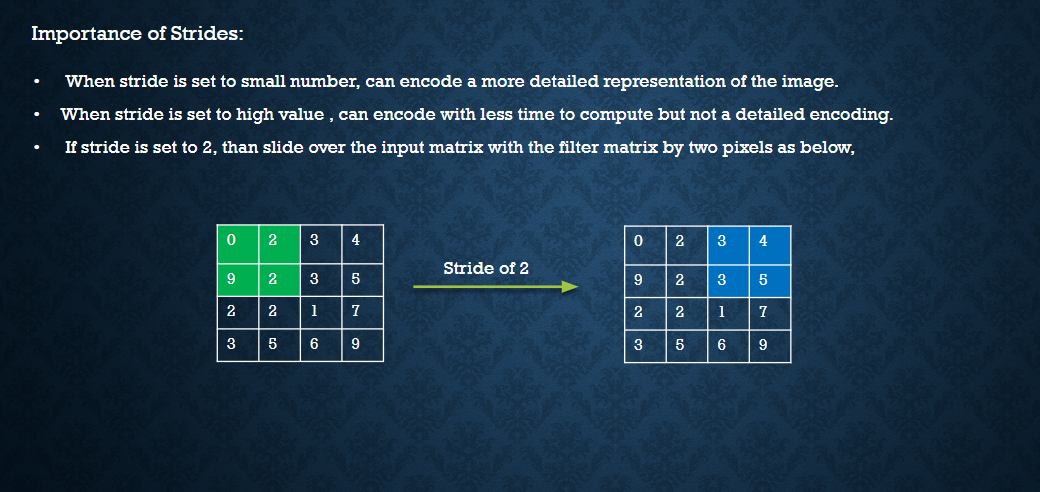

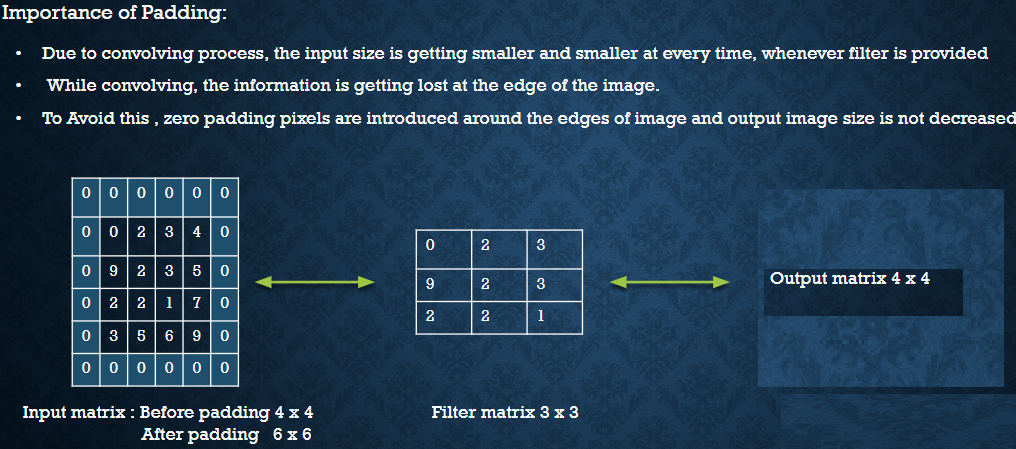

## Gaussian Kernel

It is technically Blurring the image by removing noises...Which is prerequisite to many filters and this is known as Gaussian Smoothing.

In [1]:
# Import libraries
from scipy.signal import convolve2d
import matplotlib.pyplot as plt
from skimage.io import imread
import numpy as np

In [3]:
# A Gaussian Kernel of shape 3x3 with the highest value in the center and the values deacreases as we spread out
# 1/16 in corners, 1/8 in mid, 1/4 in center
gaussian_kernel = np.array([[1/16, 1/8, 1/16],
                            [1/8, 1/4, 1/8],
                            [1/16, 1/8, 1/16]])

In [4]:
# Sum should equal one for gaussian kernel
gaussian_kernel.sum()

np.float64(1.0)

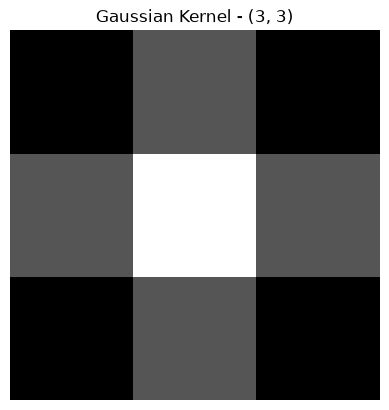

In [7]:
# Visualize the Gaussian Kernel
plt.imshow(gaussian_kernel, cmap='gray')
plt.title(f'Gaussian Kernel - {gaussian_kernel.shape}')
plt.axis('off')
plt.show()

**Link of Image:-** https://drive.google.com/uc?id=1rNc0ejiNL0duSjT172s45ZLz69vKwcuJ

In [9]:
# IMage URL
url = 'https://drive.google.com/uc?id=1rNc0ejiNL0duSjT172s45ZLz69vKwcuJ'
# Load the image as grayscale using imread of skimage for faster computation
img_gray = imread(url, as_gray=True)

In [10]:
# Check the shape of the Cartwheel Galaxy image array
img_gray.shape

(1840, 2000)

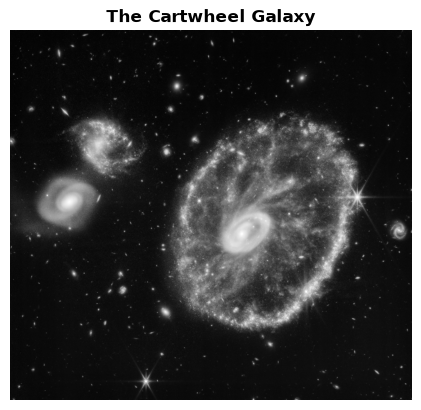

In [12]:
# Display the image
plt.imshow(img_gray, cmap='gray')
plt.title('The Cartwheel Galaxy', color='black', weight='bold')
plt.axis('off')
plt.show()

In [13]:
# Convolve the img_gray now with the gaussian kernel and make sure output shape is same as input shape
convolved_gaussian_image = convolve2d(img_gray, gaussian_kernel, mode='same')

In [14]:
# Function to plot images side by side
def comparison(image_array1, title1, image_array2, title2,
               cmap='gray', figure_size=(10, 10), show_axis=False, save=False, title_save='Image_Saved'):
    """
    Plot side-by-side image comparison for two image arrays.

    Args:
        image_array1: First image to be displayed on the left.
        title1: Title for the first image.
        image_array2: Second image to be displayed on the right.
        title2: Title for the second image.
        cmap: Colormap for both images. Default is 'gray'.
        figure_size: Tuple specifying figure size (width, height). Default is (10, 10).
        show_axis: Boolean to show or hide axis. Default is False.
        save: Boolean to save the image. Default is False.
        title_save: Filename for saving the image (without extension). Default is 'Image_Saved'.

    Returns:
        None: Displays the comparison plot and optionally saves the image.
    """
    plt.figure(figsize=figure_size)

    for idx, (image, title, color) in enumerate([(image_array1, title1, 'maroon'),
                                                 (image_array2, title2, 'royalblue')]):
        plt.subplot(1, 2, idx+1)
        plt.imshow(image, cmap=cmap)
        plt.title(title, color=color, weight='bold')
        if not show_axis:
            plt.axis('off')

    plt.tight_layout()

    if save:
        plt.savefig(f'{title_save}.png')
    plt.show()


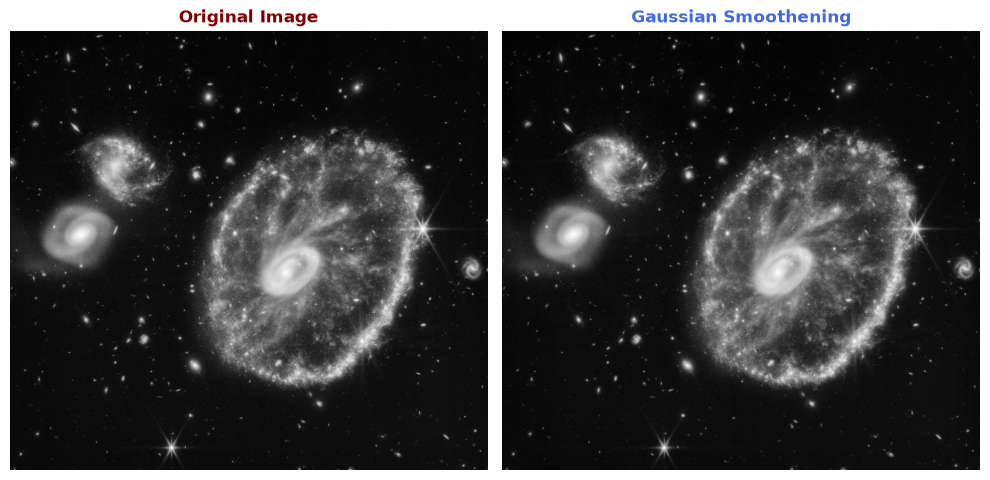

In [17]:
# Compare the original image with convolved gaussian image
comparison(img_gray, 'Original Image',
           convolved_gaussian_image, 'Gaussian Smoothening',
           save=True, title_save='SelfGaussianKernel')

### Introducing Gaussian Filter in Scikit-image

In [18]:
from skimage.filters import gaussian

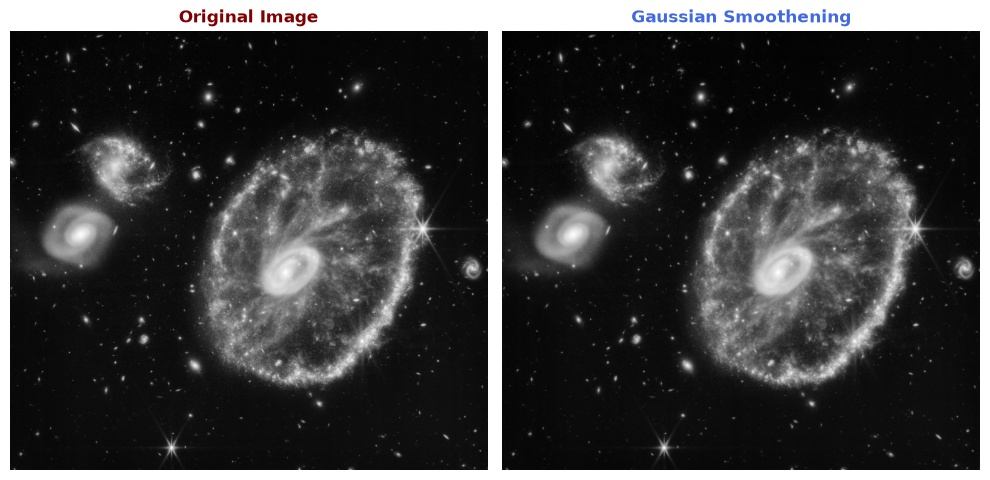

In [23]:
# Apply gaussian using skimage and change sigma values
gaussian_using_skimage = gaussian(img_gray, sigma=1, mode='nearest')
#sigma defines the std dev of the gaussian kernel and proportional to kernel size

# Plot
comparison(img_gray, 'Original Image',
           gaussian_using_skimage, 'Gaussian Smoothening',
           save=True, title_save="Comparison with Skimage's Gaussian Kernel")

This is known as Gaussian Blur Image also...

### Image_sharpening_using_unsharp_mask



> Unsharp mask enhances edges by subtracting an unsharp (smoothed) version of the image from the original.Effectively making the filter a high pass filter.

> Enhanced image = original + amount * (original - blurred)

> Amount of sharpening can be controlled via scaling factor, a multiplication factor for the sharpened signal.

> skimage uses Gaussian smoothing for image blurring therefore the radius parameter in the unsharp masking filter refers to the sigma parameter of the gaussian filter.

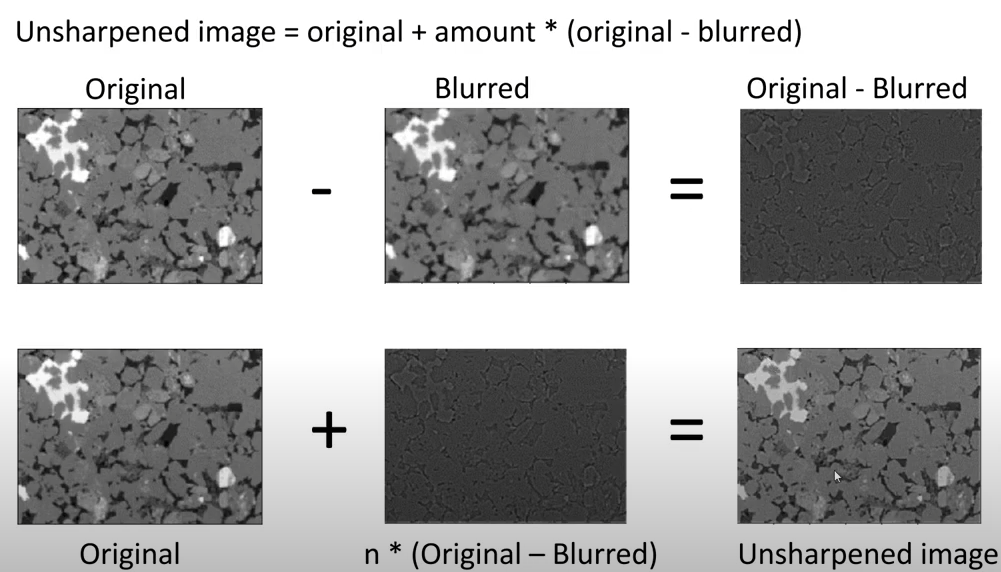

min: -0.3428,
max:  2.2111


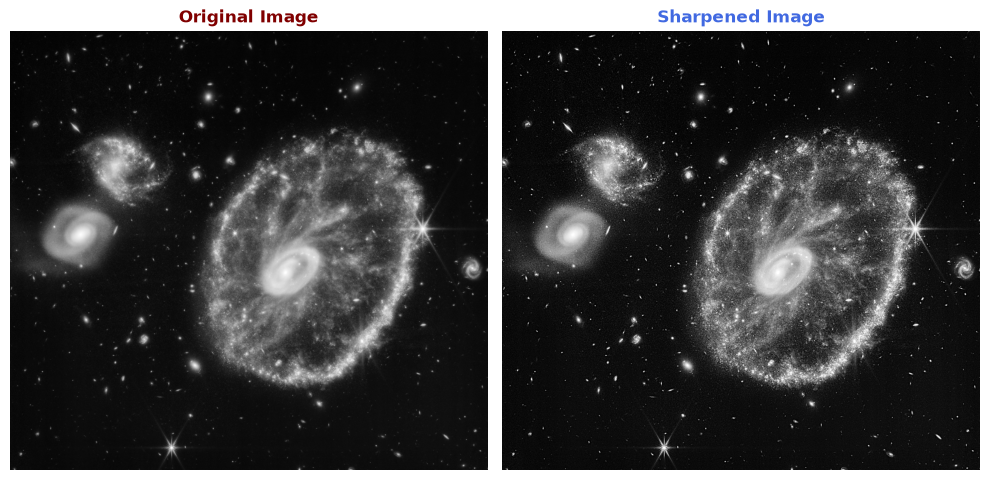

In [32]:
# Manually Create unsharp_mask and implement it on img_gray

# User controls
sharpening_amount = 2
std_dev = 3

# Unsharp mask
blur = gaussian(img_gray, sigma=std_dev)
subtraction = img_gray - blur
unsharp_out = img_gray + sharpening_amount * subtraction
print(f"min: {unsharp_out.min():7.4f},\nmax: {unsharp_out.max():7.4f}")

# Clip the outputs to bring the sharpening effect
np.clip(unsharp_out, 0, 1, out=unsharp_out)

# if in unsharp_out if values are < 0 then set all these values to 0
# if in unsharp_out if values are > 1 then set all these values to 1

# Comparison
comparison(img_gray, 'Original Image',
           unsharp_out, 'Sharpened Image')

## Unsharp Mask through skimage

In [26]:
from skimage.filters import unsharp_mask

min:  0.0000,
max:  1.0000


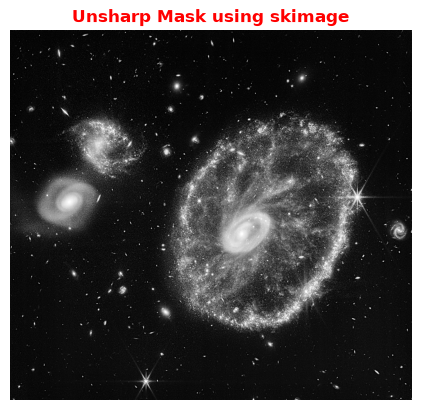

In [34]:

unsharped_img = unsharp_mask(img_gray, radius=3, amount=2, preserve_range=False) # preserve_range doesn't clip the values of pixels. By default it is false.
#Check more:- https://github.com/scikit-image/scikit-image/blob/main/skimage/filters/_unsharp_mask.py

print(f"min: {unsharped_img.min():7.4f},\nmax: {unsharped_img.max():7.4f}")

plt.imshow(unsharped_img, cmap='gray')
plt.title('Unsharp Mask using skimage', color='red', weight='bold')
plt.axis('off')
plt.show()

In [ ]:
# Compare side by side manually and skimage unsharp filter output on img_gray
comparison(unsharp_out, 'Manual Output',
           unsharped_img, 'Skimage Output',
           save=True,title_save='Comparision of Gaussian Outputs')